# Latihan Praktikum Bab 6: KNN dan Naive Bayes
Bab ini memakai dataset yang berbeda dari bab sebelumnya: **Breast Cancer** (bawaan scikit-learn) untuk Praktikum 1 dan **teks spam sederhana** (ada di buku) untuk Praktikum 2. Jalankan dari atas ke bawah (**Shift+Enter** pada tiap sel), atau **Runtime → Run all**.

---
# Praktikum 1: KNN vs Naive Bayes (load_breast_cancer)
KNN memakai scaling, Gaussian Naive Bayes tanpa scaling (tidak membutuhkannya). Bandingkan akurasi, waktu pelatihan, dan waktu prediksi dengan modul `time`.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target
print("Ukuran data:", X.shape, "| Kelas:", dict(zip(data.target_names, np.bincount(y))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

Ukuran data: (569, 30) | Kelas: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


In [2]:
# Satu kali ukur (seperti instruksi buku)
knn = KNeighborsClassifier(n_neighbors=5)
t0 = time.perf_counter(); knn.fit(X_train_scaled, y_train); waktu_latih_knn = time.perf_counter() - t0
t0 = time.perf_counter(); pred_knn = knn.predict(X_test_scaled); waktu_pred_knn = time.perf_counter() - t0

nb = GaussianNB()
t0 = time.perf_counter(); nb.fit(X_train, y_train); waktu_latih_nb = time.perf_counter() - t0
t0 = time.perf_counter(); pred_nb = nb.predict(X_test); waktu_pred_nb = time.perf_counter() - t0

hasil = pd.DataFrame({
    "Model": ["KNN (k=5, scaled)", "Gaussian NB"],
    "Akurasi": [accuracy_score(y_test, pred_knn), accuracy_score(y_test, pred_nb)],
    "Waktu latih (ms)": [waktu_latih_knn * 1000, waktu_latih_nb * 1000],
    "Waktu prediksi (ms)": [waktu_pred_knn * 1000, waktu_pred_nb * 1000],
}).round(4)
hasil

,Model,Akurasi,Waktu latih (ms),Waktu prediksi (ms)
0,"KNN (k=5, scaled)",0.9561,0.6008,11.1833
1,Gaussian NB,0.9386,0.9872,0.2036


In [3]:
# Pengukuran lebih andal: ulangi 200 kali lalu ambil rata-rata
def ukur(buat_model, Xa, Xb, n=200):
    lt, lp = [], []
    for _ in range(n):
        m = buat_model()
        t0 = time.perf_counter(); m.fit(Xa, y_train); lt.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); m.predict(Xb); lp.append(time.perf_counter() - t0)
    return np.mean(lt) * 1000, np.mean(lp) * 1000

latih_k, pred_k = ukur(lambda: KNeighborsClassifier(n_neighbors=5), X_train_scaled, X_test_scaled)
latih_n, pred_n = ukur(GaussianNB, X_train, X_test)
pd.DataFrame({
    "Model": ["KNN (k=5, scaled)", "Gaussian NB"],
    "Rata-rata waktu latih (ms)": [latih_k, latih_n],
    "Rata-rata waktu prediksi (ms)": [pred_k, pred_n],
}).round(3)

,Model,Rata-rata waktu latih (ms),Rata-rata waktu prediksi (ms)
0,"KNN (k=5, scaled)",0.287,0.452
1,Gaussian NB,0.505,0.115


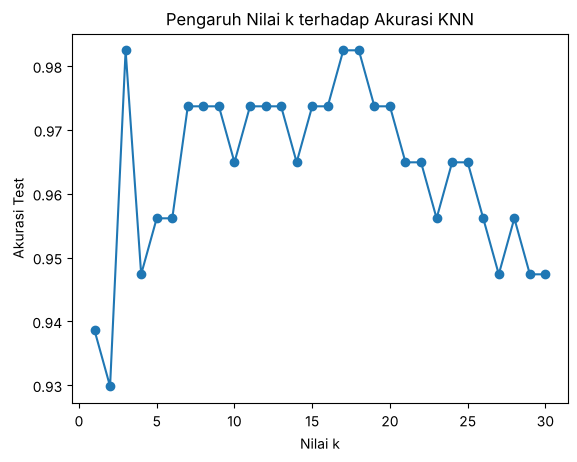

In [4]:
# Tambahan: pengaruh nilai k pada KNN (kode di bagian 6.16)
nilai_k = range(1, 31)
akurasi_k = []
for k in nilai_k:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    akurasi_k.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.plot(nilai_k, akurasi_k, marker='o')
plt.xlabel("Nilai k"); plt.ylabel("Akurasi Test")
plt.title("Pengaruh Nilai k terhadap Akurasi KNN")
plt.show()

**Kesimpulan Praktikum 1 (isi/sesuaikan dengan output Anda):**
- **Akurasi:** KNN (0,956) sedikit lebih tinggi dari Gaussian NB (0,939). Selisihnya hanya sekitar 2 dari 114 data uji, jadi keduanya setara. Pada grafik k, akurasi KNN berkisar 0,93 sampai 0,98 dan naik-turun sesuai teori di 6.16.1.
- **Waktu pelatihan:** KNN justru sedikit lebih cepat (rata-rata sekitar 0,3 ms dibanding 0,5 ms untuk NB), karena KNN pada dasarnya hanya menyimpan data (*lazy learner*), sedangkan NB menghitung mean dan varians tiap fitur. Pada data sekecil ini kedua waktu sangat kecil.
- **Waktu prediksi:** NB jauh lebih cepat (sekitar 0,12 ms dibanding 0,45 ms) karena KNN harus menghitung jarak ke semua data latih untuk setiap prediksi. Selisih ini akan makin besar pada data yang lebih banyak.
- **Catatan:** pengukuran satu kali bisa menyesatkan (prediksi KNN pertama tampak 10 ms karena proses awal), jadi saya tambahkan pengukuran rata-rata 200 kali. Angka waktu di komputer Anda akan berbeda, tetapi pola prediksi NB lebih cepat biasanya sama.

---
# Praktikum 2: Klasifikasi Teks dengan Multinomial Naive Bayes (Praktikum 6.7)
Dataset: 6 kalimat sederhana (1 = spam, 0 = bukan spam). Kode ini persis dari buku.

In [5]:
# Praktikum 6.7 (kode di buku)
teks = ["dapatkan diskon gratis sekarang",
        "rapat tim jam 10 pagi",
        "menangkan hadiah gratis klik disini",
        "laporan keuangan bulan ini", "diskon spesial hari ini",
        "jadwal kuliah minggu depan"]
label = [1, 0, 1, 0, 1, 0]  # 1 = spam, 0 = bukan spam

vectorizer = CountVectorizer()
X_teks = vectorizer.fit_transform(teks)
model = MultinomialNB(alpha=1.0)  # alpha = parameter Laplace Smoothing
model.fit(X_teks, label)

teks_baru = ["diskon gratis hari ini"]
prediksi = model.predict(vectorizer.transform(teks_baru))
print("Prediksi:", "Spam" if prediksi[0] == 1 else "Bukan Spam")

Prediksi: Spam


In [6]:
# Tambahan: lihat probabilitas dan kata-kata yang dipakai
print("Kosakata:", list(vectorizer.get_feature_names_out()))
proba = model.predict_proba(vectorizer.transform(teks_baru))[0]
print(f"P(bukan spam)={proba[0]:.3f}, P(spam)={proba[1]:.3f}")

# Kata paling kuat menunjuk spam
selisih = model.feature_log_prob_[1] - model.feature_log_prob_[0]
kata = vectorizer.get_feature_names_out()
urut = np.argsort(selisih)[::-1][:5]
print("Kata paling menunjuk spam:", [kata[i] for i in urut])

Kosakata: ['10', 'bulan', 'dapatkan', 'depan', 'disini', 'diskon', 'gratis', 'hadiah', 'hari', 'ini', 'jadwal', 'jam', 'keuangan', 'klik', 'kuliah', 'laporan', 'menangkan', 'minggu', 'pagi', 'rapat', 'sekarang', 'spesial', 'tim']
P(bukan spam)=0.053, P(spam)=0.947
Kata paling menunjuk spam: ['diskon', 'gratis', 'spesial', 'hari', 'klik']


In [7]:
# Tambahan: pengaruh Laplace smoothing (alpha) dan kata yang belum pernah muncul
uji = ["diskon gratis hari ini", "rapat gratis jam 10", "hadiah menarik untuk anda"]
for a in [0.01, 1.0, 10.0]:
    m = MultinomialNB(alpha=a).fit(X_teks, label)
    p = m.predict_proba(vectorizer.transform(uji))[:, 1]
    print(f"alpha={a:>5}:", [f"{v:.3f}" for v in p])

alpha= 0.01: ['1.000', '0.000', '0.990']
alpha=  1.0: ['0.947', '0.273', '0.667']
alpha= 10.0: ['0.613', '0.474', '0.524']


**Kesimpulan Praktikum 2 (isi/sesuaikan dengan output Anda):**
- Teks baru "diskon gratis hari ini" diprediksi **Spam** (probabilitas spam sekitar 0,95). Kata `diskon`, `gratis`, dan `hari` muncul di contoh spam saat pelatihan.
- Multinomial NB bekerja dengan menghitung frekuensi kata per kelas (CountVectorizer mengubah teks menjadi hitungan kata).
- **Laplace smoothing (`alpha`)** mencegah probabilitas nol untuk kata yang tidak pernah muncul di salah satu kelas. Dengan `alpha` sangat kecil (0,01) model terlalu yakin (probabilitas mendekati 1,000 atau 0,000), sedangkan `alpha` besar (10) membuat model ragu-ragu (mendekati 0,5). `alpha=1,0` adalah titik tengah yang wajar.
- Keterbatasan: hanya 6 contoh data, jadi hasilnya hanya untuk latihan dan tidak mewakili performa nyata. Kata yang tidak ada di kosakata (misalnya `menarik`, `anda`) diabaikan oleh model.